# Checks, grid algebra, correlations and trends

Gridded data look authoritative: every cell has a number. This notebook teaches the checks that tell you whether to
believe those numbers, and the calculations most studies need, on the two rainfall products over Punjab prepared in
notebook 2 (CHIRPS and ERA5-Land, 2001-2024, same 0.1 degree grid):

* **sanity checks**: units, ranges, missing values, gaps in time;
* **algebra between grids**: differences, ratios, percentage change, standardised anomalies;
* **checking one product against another**, and finding a fault in one of them;
* **correlation**: in time, between products, detrended, lagged, and as a map; and how many independent values a
  correlation really rests on;
* **trends in every cell**, and why testing thousands of cells at once needs a correction.

Nothing here is specific to rainfall: the same steps apply to temperature, aerosol, snow cover or GRACE water storage.

In [1]:
import importlib.util, subprocess, sys
for m, p in {"xarray": "xarray", "netCDF4": "netCDF4", "scipy": "scipy"}.items():
    if importlib.util.find_spec(m) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", p], check=True)
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt, requests
from scipy import stats
plt.rcParams.update({"figure.dpi": 110})
DATA = Path("gd_data"); f = DATA / "punjab_rain_two_products.nc"
if not f.exists():                                            # made by notebook 2
    DATA.mkdir(exist_ok=True)
    f.write_bytes(requests.get("https://raw.githubusercontent.com/AhmadAmmar/AhmadAmmar.github.io/main/guides/gridded-data/notebooks/gd_data/punjab_rain_two_products.nc", timeout=600).content)
ds = xr.open_dataset(f)
ds

<xarray.Dataset> Size: 19MB
Dimensions:    (time: 288, longitude: 101, latitude: 81)
Coordinates:
  * time       (time) datetime64[ns] 2kB 2001-01-01 2001-02-01 ... 2024-12-01
  * longitude  (longitude) float64 808B 70.0 70.1 70.2 70.3 ... 79.8 79.9 80.0
  * latitude   (latitude) float64 648B 26.0 26.1 26.2 26.3 ... 33.8 33.9 34.0
Data variables:
    chirps     (time, latitude, longitude) float32 9MB ...
    era5       (time, latitude, longitude) float32 9MB ...
Attributes:
    title:        Monthly rainfall over Punjab, two products on one grid
    Conventions:  CF-1.8
    source:       CHIRPS v2.0 via IRI Data Library; ERA5-Land via Copernicus CDS
    history:      made by gd_netcdf_xarray.ipynb on 2026-11-21

# Sanity checks before any analysis

Five questions, each one line of code: are the **units** what you think; are the **values in a plausible range**
(rain cannot be negative); how many are **missing**; is the **time axis complete** (no skipped months, no duplicates);
and do both products cover the **same cells**?

In [2]:
def sanity(da):
    t = pd.DatetimeIndex(da.time.values)
    expected = pd.date_range(t.min(), t.max(), freq="MS")
    return {"units": da.attrs.get("units"), "min": float(da.min()), "max": float(da.max()),
            "negative values": int((da < 0).sum()), "missing %": round(100 * float(da.isnull().mean()), 2),
            "months missing": len(expected.difference(t)), "duplicated months": int(t.duplicated().sum())}
pd.DataFrame({k: sanity(ds[k]) for k in ("chirps", "era5")})

,chirps,era5
units,mm/month,mm/month
min,0.0,0.009673
max,1299.773682,2022.823975
negative values,0,0
missing %,4.4,0.0
months missing,0,0
duplicated months,0,0


# Algebra between grids

Because both products share a grid, arithmetic works cell by cell and month by month: xarray lines up the coordinates
for you. Four calculations you will use again and again:

* **difference** `a - b` (same units): where and by how much they disagree;
* **ratio** `a / b`: the relative size, independent of how wet a place is;
* **percentage change** between two periods: `100 * (later - earlier) / earlier`;
* **standardised anomaly** `(x - mean) / standard deviation`: how unusual a value is, comparable between places.

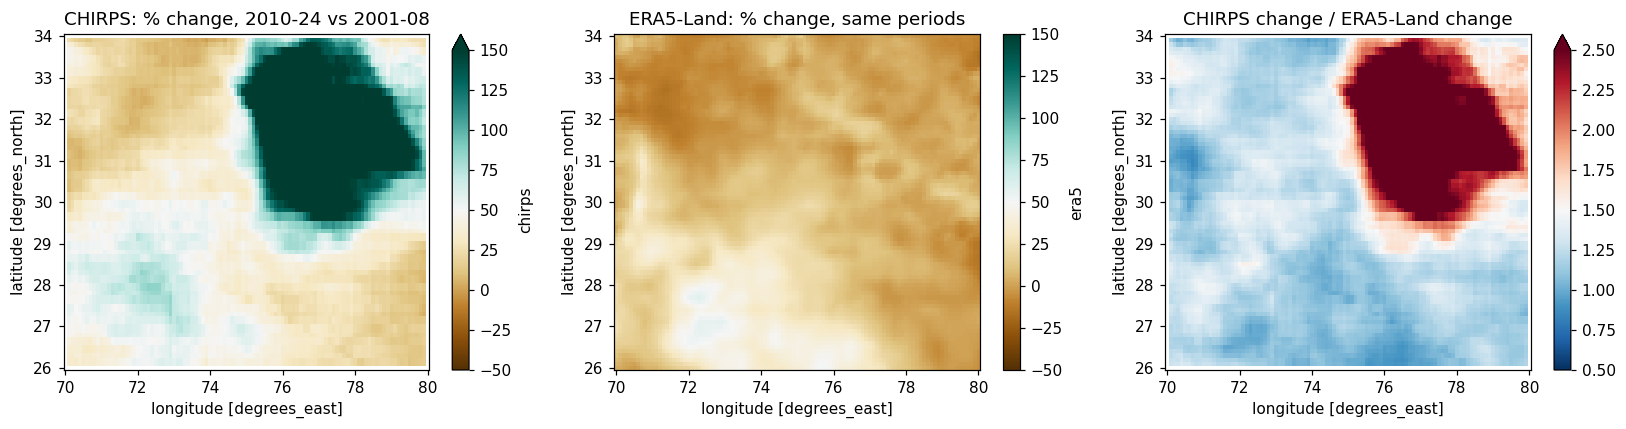

In [3]:
yr = ds.resample(time="YS").sum()                              # annual totals, mm/yr
early, late = yr.sel(time=slice("2001", "2008")).mean("time"), yr.sel(time=slice("2010", "2024")).mean("time")
change = 100 * (late - early) / early                          # % change in each product
ratio_of_changes = (late.chirps / early.chirps) / (late.era5 / early.era5)
z = (yr - yr.mean("time")) / yr.std("time")                    # standardised annual anomalies
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
change.chirps.plot(ax=ax[0], vmin=-50, vmax=150, cmap="BrBG"); ax[0].set_title("CHIRPS: % change, 2010-24 vs 2001-08")
change.era5.plot(ax=ax[1], vmin=-50, vmax=150, cmap="BrBG"); ax[1].set_title("ERA5-Land: % change, same periods")
ratio_of_changes.plot(ax=ax[2], vmin=0.5, vmax=2.5, cmap="RdBu_r"); ax[2].set_title("CHIRPS change / ERA5-Land change")
plt.tight_layout(); plt.show()

# One product against another: finding a fault

Real changes in climate appear in every good product; a fault appears in one. On the right-hand map CHIRPS grew
somewhat more than ERA5-Land almost everywhere (ratios of 1 to 1.5), but over Indian Punjab and the Himachal foothills
it grew two to three times more: a sharp-edged patch, which climate does not draw. Average the two products over
that patch, year by year:

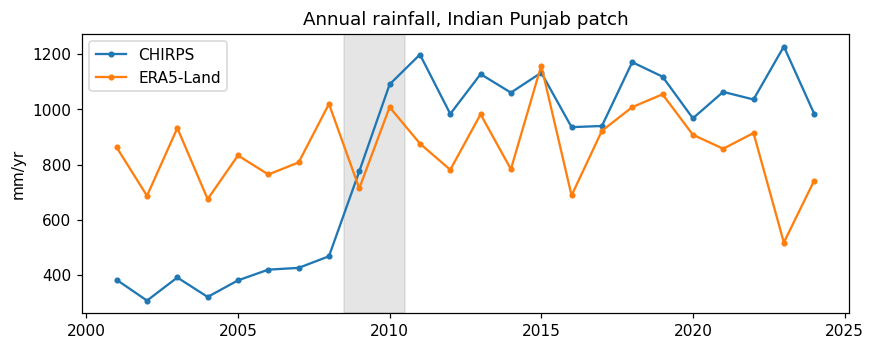

time    2001-01-01  2002-01-01  2003-01-01  2004-01-01  2005-01-01  \
chirps       383.0       308.0       391.0       321.0       381.0   
era5         862.0       687.0       932.0       675.0       833.0   

time    2006-01-01  2007-01-01  2008-01-01  2009-01-01  2010-01-01  ...  \
chirps       420.0       426.0       468.0       775.0      1090.0  ...   
era5         764.0       808.0      1019.0       714.0      1008.0  ...   

time    2015-01-01  2016-01-01  2017-01-01  2018-01-01  2019-01-01  \
chirps      1132.0       935.0       939.0      1170.0      1118.0   
era5        1158.0       688.0       922.0      1008.0      1054.0   

time    2020-01-01  2021-01-01  2022-01-01  2023-01-01  2024-01-01  
chirps       967.0      1063.0      1035.0      1227.0       984.0  
era5         908.0       857.0       914.0       518.0       742.0  

[2 rows x 24 columns]


In [4]:
patch = dict(latitude=slice(30, 32), longitude=slice(74.5, 77))
s = yr.sel(**patch).weighted(np.cos(np.deg2rad(yr.latitude.sel(latitude=patch["latitude"])))).mean(["latitude", "longitude"])
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(s.time.dt.year, s.chirps, "-o", ms=3, label="CHIRPS"); ax.plot(s.time.dt.year, s.era5, "-o", ms=3, label="ERA5-Land")
ax.axvspan(2008.5, 2010.5, color="grey", alpha=.2); ax.set_ylabel("mm/yr"); ax.legend(); ax.set_title("Annual rainfall, Indian Punjab patch")
plt.show()
print(s.to_dataframe()[["chirps", "era5"]].round(0).T)

CHIRPS roughly doubles in two years and stays there; ERA5-Land shows nothing like it. CHIRPS blends satellite
estimates with station reports, so the most likely cause is a change in the stations it used here around 2009-2010:
a step in the product, not in the sky. (The decisive check is the rain gauges themselves, e.g. the India Meteorological
Department's gridded rainfall; that is a good exercise.) A trend computed from CHIRPS here would
be mostly this step. **The lesson: before trusting a trend from one gridded product, compare it with a second,
independent one.** (When two products disagree, neither is automatically right: check against gauges where you can.)

# Correlation in time

Pearson's *r* measures how closely two series move together (straight-line relation); Spearman's *rho* uses ranks and
is safer with skewed data such as rainfall. Three pitfalls, shown below:

1. **Seasons inflate correlation.** Two monthly rainfall series correlate highly just because both have a monsoon.
   Correlate anomalies (season removed) to ask whether they agree on *unusual* months.
2. **Shared trends inflate correlation.** Remove the linear trend (detrend) first, or a step like the one above
   changes *r*.
3. **Neighbouring values are not independent.** Autocorrelation reduces the effective number of values, so the usual
   p-value is too small. A standard correction: n_eff = n (1 - r1 r2) / (1 + r1 r2), with r1, r2 the lag-1
   autocorrelations of the two series.

In [5]:
a = ds.chirps.sel(latitude=30.9, longitude=75.85, method="nearest").to_series()
b = ds.era5.sel(latitude=30.9, longitude=75.85, method="nearest").to_series()
anom = lambda x: x - x.groupby(x.index.month).transform("mean")
def detrend(x):
    t = np.arange(len(x)); return x - np.polyval(np.polyfit(t, x.values, 1), t)
def r_with_neff(x, y):
    r = np.corrcoef(x, y)[0, 1]; r1, r2 = x.autocorr(1), y.autocorr(1); n = len(x)
    neff = n * (1 - r1 * r2) / (1 + r1 * r2); tval = r * np.sqrt((neff - 2) / (1 - r ** 2))
    return r, n, neff, 2 * stats.t.sf(abs(tval), neff - 2)
rows = []
for name, x, y in (("monthly totals", a, b), ("monthly anomalies", anom(a), anom(b)), ("anomalies, detrended", detrend(anom(a)), detrend(anom(b)))):
    r, n, neff, p = r_with_neff(x, y)
    rows.append({"series": name, "pearson r": r, "spearman rho": stats.spearmanr(x, y)[0], "n": n, "effective n": neff, "p (effective n)": p})
pd.DataFrame(rows).round(3)

,series,pearson r,spearman rho,n,effective n,p (effective n)
0,monthly totals,0.758,0.819,288,184.332,0.0
1,monthly anomalies,0.384,0.426,288,261.691,0.0
2,"anomalies, detrended",0.420,0.396,288,270.519,0.0


# Lagged correlation

Does one series lead the other? Shift one by k months and correlate again. For two rainfall products the peak should be
at lag 0; a peak elsewhere would mean a dating error. The same tool asks real questions: does groundwater respond to
rain one, two or three months later?

In [6]:
lags = range(-3, 4)
pd.Series({k: anom(a).corr(anom(b).shift(k)) for k in lags}, name="r").rename_axis("lag (months; + = ERA5-Land later)").round(3).to_frame().T

lag (months; + = ERA5-Land later),-3,-2,-1,0,1,2,3
r,0.01,0.033,0.031,0.384,-0.07,-0.017,-0.064


# A correlation map

Compute the correlation in every cell at once with `xr.corr` along time. Where the map is low, the two products
disagree about which months were unusually wet or dry.

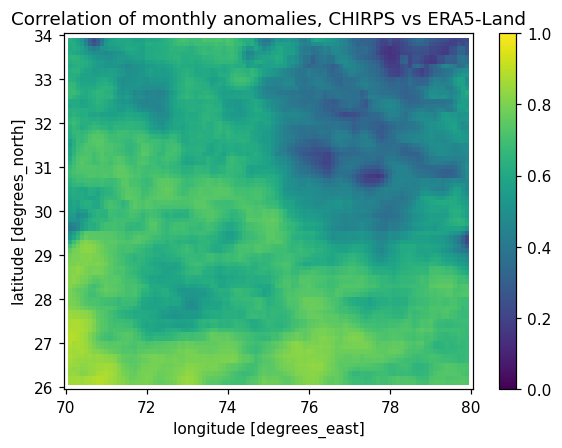

median correlation over the box: 0.63


In [7]:
an = ds.groupby("time.month") - ds.groupby("time.month").mean()
rmap = xr.corr(an.chirps, an.era5, dim="time")
ax = rmap.plot(vmin=0, vmax=1, cmap="viridis", figsize=(6, 4.2)); plt.title("Correlation of monthly anomalies, CHIRPS vs ERA5-Land"); plt.show()
print("median correlation over the box:", round(float(rmap.median()), 2))

# A trend in every cell, and the many-tests problem

A per-cell trend is a regression of each cell's annual totals on the year. `polyfit` does it for all cells at once.
The significance test needs care twice over: autocorrelation (as above), and **multiple testing**. Test 8,000 cells at
p < 0.05 and about 400 will look significant by chance alone. The **false discovery rate** (Benjamini-Hochberg) keeps
the expected share of false positives among the cells you call significant below 5 %.

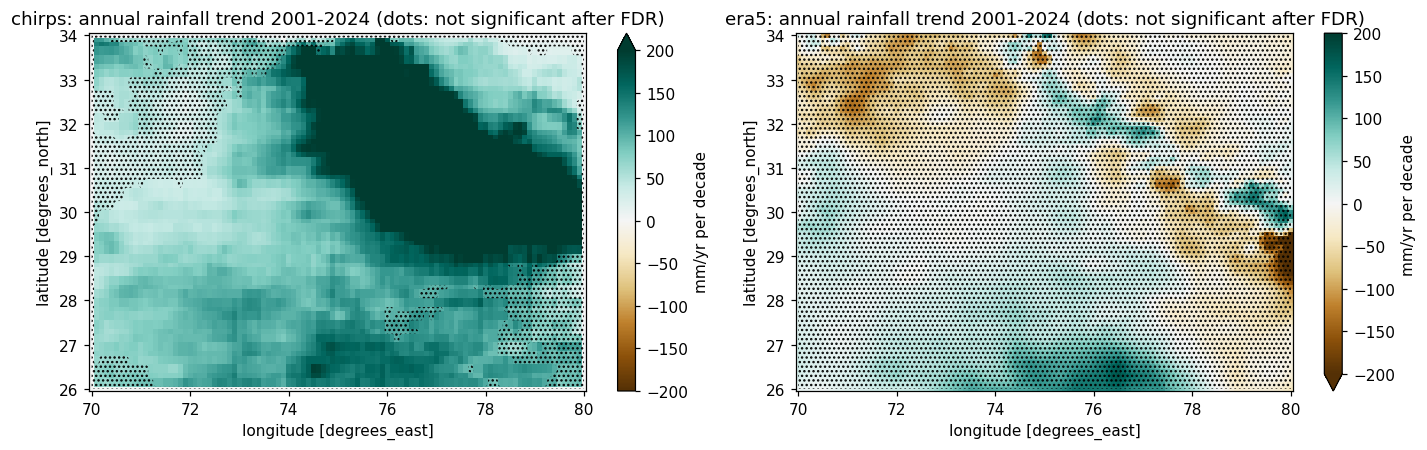

,chirps,era5
cells p<0.05,6630,378
cells significant after FDR,6495,0
cells,8181,8181


In [8]:
def trend_map(da):
    fit = da.polyfit("time", 1)                                   # time in nanoseconds: rescale to per decade
    slope = fit.polyfit_coefficients.sel(degree=1) * 1e9 * 3600 * 24 * 365.25 * 10
    t = np.arange(da.sizes["time"]); y = da.transpose("time", ...).values.reshape(len(t), -1)
    p = np.array([stats.linregress(t, c).pvalue if np.isfinite(c).all() else np.nan for c in y.T]).reshape(da.shape[1:])
    return slope, xr.DataArray(p, coords=slope.coords, dims=slope.dims)
def fdr(p, q=0.05):
    v = p.values.ravel(); ok = np.isfinite(v); s = np.sort(v[ok]); m = ok.sum()
    k = np.where(s <= q * np.arange(1, m + 1) / m)[0]; cut = s[k.max()] if len(k) else 0
    return p <= cut
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2)); out = {}
for a_, k in zip(ax, ("chirps", "era5")):
    slope, p = trend_map(yr[k]); sig = fdr(p)
    slope.plot(ax=a_, vmin=-200, vmax=200, cmap="BrBG", cbar_kwargs={"label": "mm/yr per decade"})
    a_.contourf(slope.longitude, slope.latitude, (~sig).astype(int), levels=[.5, 1.5], hatches=["...."], colors="none")
    a_.set_title(f"{k}: annual rainfall trend 2001-2024 (dots: not significant after FDR)")
    out[k] = {"cells p<0.05": int((p < .05).sum()), "cells significant after FDR": int(sig.sum()), "cells": int(np.isfinite(p).sum())}
plt.tight_layout(); plt.show()
pd.DataFrame(out)

CHIRPS shows a strong, "significant" wetting trend over Indian Punjab; ERA5-Land does not. Every check above points
the same way: that trend is the 2009-2010 step in CHIRPS, not climate.

# A checklist for any gridded dataset

1. Read the attributes: units, time axis, calendar, missing-value code, scale factor.
2. Check ranges, missing values and gaps in time.
3. Sort coordinates (latitude south to north, longitude -180 to 180) before slicing.
4. Convert units explicitly, and write the units into your outputs.
5. Weight area averages by cell area.
6. Compare against a second, independent product (or gauges) before trusting a trend.
7. Remove seasons and trends before correlating; count effective, not nominal, values.
8. Correct for multiple testing when you test many cells.